<a href="https://colab.research.google.com/github/Sebas086/aprendizaje-automatico-f1/blob/main/03_agrupamiento_jerarquico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/andres-merino/AprendizajeAutomaticoInicial-05-N0105/blob/main/2-Ejercicios/03-Agrupamiento-Jerarquico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="border: none; border-collapse: collapse;">
    <tr>
        <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
            <img src="https://i.imgur.com/nt7hloA.png" width="100">
        </td>
        <td style="width: 2px; text-align: center;">
            <font color="#0030A1" size="7">|</font><br>
            <font color="#0030A1" size="7">|</font>
        </td>
        <td>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
                <b>Facultad de Ciencias Exactas, Naturales y Ambientales</b>
            </font> </p>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
                Aprendizaje Automático Inicial &bull; Agrupamiento Jerarquico
            </font></p>
            <p style="font-style: oblique;"><font color="#0030A1" size="3">
                Andrés Merino &bull; 2025-04
            </font></p>
        </td>  
    </tr>
</table>

**Estudiante:** Sebastián Haro

---
## <font color='264CC7'> Introducción </font>


A lo largo de este taller, aplicaremos el algoritmo de agrupamiento jerárquico a un conjunto de datos históricos de Fórmula 1 (resultados de temporadas de pilotos de 1950 a 2024).


Los paquetes necesarios son:

In [ ]:
# Instalar dependencia si no está disponible
!pip install -q kagglehub[pandas-datasets]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import kagglehub
from kagglehub import KaggleDatasetAdapter
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

---
## <font color='264CC7'> Preprocesamiento de datos </font>



Cargamos directamente `drivers_updated.csv` del dataset de Kaggle mediante `KaggleDatasetAdapter.PANDAS`. Como el dataset original contiene registros por temporada (`Pos`, `Driver`, `Nationality`, `Car`, `PTS`, `year`, `Code`), agrupamos los 398 pilotos históricos para construir un conjunto de variables numéricas consistentes:
- `Temporadas`: Número de temporadas disputadas.
- `Puntos_Totales`: Suma histórica de puntos obtenidos (`PTS`).
- `Promedio_Puntos`: Promedio de puntos por temporada.
- `Mejor_Posicion`: Mejor posición final alcanzada en un campeonato (1 = Campeón).
- `Posicion_Promedio`: Posición promedio en el campeonato a lo largo de su carrera.
- `Equipos_Distintos`: Número de escuderías diferentes con las que compitió.

**Ejercicio:**
Carga el conjunto de datos y procésalos:
- Muestra algunos datos.
- Muestra una descripción de los datos.
- Escala los datos si es necesario.

In [ ]:
# Carga directa como DataFrame de Pandas usando dataset_load
df_raw = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "lakshayjain611/f1-races-results-dataset-1950-to-2024",
    "drivers_updated.csv"
)

print("Primeros 5 registros del dataset original:")
display(df_raw.head())

# Limpieza de nombres (corregir codificación latin1->utf8 y dobles espacios)
def limpiar_nombre(texto):
    s = str(texto)
    try:
        s = s.encode('latin1').decode('utf-8')
    except Exception:
        pass
    return ' '.join(s.split())

df_raw['Driver'] = df_raw['Driver'].apply(limpiar_nombre)
df_raw['Pos'] = pd.to_numeric(df_raw['Pos'], errors='coerce')
df_raw['PTS'] = pd.to_numeric(df_raw['PTS'], errors='coerce').fillna(0)
df_raw = df_raw.dropna(subset=['Pos'])

# Agregación por piloto para obtener el perfil numérico (398 pilotos)
df_pilotos = df_raw.groupby('Driver').agg(
    Temporadas=('year', 'nunique'),
    Puntos_Totales=('PTS', 'sum'),
    Promedio_Puntos=('PTS', 'mean'),
    Mejor_Posicion=('Pos', 'min'),
    Posicion_Promedio=('Pos', 'mean'),
    Equipos_Distintos=('Car', 'nunique')
)

print("\nMuestra de datos procesados por piloto (primeros 10):")
display(df_pilotos.head(10))

print("\nDescripción estadística de los datos:")
display(df_pilotos.describe().round(2))

# Escalamiento estándar (necesario porque Puntos_Totales llega a 4681.5 y Equipos_Distintos a 9)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_pilotos)
df_scaled = pd.DataFrame(X_scaled, columns=df_pilotos.columns, index=df_pilotos.index)

print("\nMuestra de datos escalados (StandardScaler):")
display(df_scaled.head())

Using Colab cache for faster access to the 'f1-races-results-dataset-1950-to-2024' dataset.
Primeros 5 registros del dataset original:


,Pos,Driver,Nationality,Car,PTS,year,Code
0,1,Nino Farina,ITA,Alfa Romeo,30.0,1950,FAR
1,2,Juan Manuel Fangio,ARG,Alfa Romeo,27.0,1950,FAN
2,3,Luigi Fagioli,ITA,Alfa Romeo,24.0,1950,FAG
3,4,Louis Rosier,FRA,Talbot-Lago,13.0,1950,ROS
4,5,Alberto Ascari,ITA,Ferrari,11.0,1950,ASC



Muestra de datos procesados por piloto (primeros 10):


,Temporadas,Puntos_Totales,Promedio_Puntos,Mejor_Posicion,Posicion_Promedio,Equipos_Distintos
Driver,,,,,,
Adrian Sutil,7,124.0,17.714286,9.0,15.285714,4
Aguri Suzuki,3,8.0,2.666667,12.0,15.666667,3
Alain Prost,13,768.5,59.115385,1.0,3.461538,6
Alan Brown,1,2.0,2.000000,16.0,16.000000,1
Alan Jones,8,199.0,24.875000,1.0,8.500000,5
Alberto Ascari,5,107.6,21.520000,1.0,6.800000,2
Alessandro Nannini,3,65.0,21.666667,6.0,8.000000,1
Alessandro Zanardi,1,1.0,1.000000,20.0,20.000000,1
Alex Caffi,2,6.0,3.000000,16.0,17.500000,2



Descripción estadística de los datos:


,Temporadas,Puntos_Totales,Promedio_Puntos,Mejor_Posicion,Posicion_Promedio,Equipos_Distintos
count,398.00,398.00,398.00,398.00,398.00,398.00
mean,4.17,129.76,13.82,11.53,14.40,2.44
std,3.99,411.07,30.23,6.94,5.31,1.83
min,1.00,0.00,0.00,1.00,2.88,0.00
25%,1.00,2.00,2.00,6.00,10.50,1.00
50%,3.00,10.00,4.00,12.00,15.00,2.00
75%,6.00,71.00,13.61,18.00,18.00,3.00
max,20.00,4681.50,275.55,27.00,27.00,9.00



Muestra de datos escalados (StandardScaler):


,Temporadas,Puntos_Totales,Promedio_Puntos,Mejor_Posicion,Posicion_Promedio,Equipos_Distintos
Driver,,,,,,
Adrian Sutil,0.709833,-0.014018,0.129000,-0.364249,0.167444,0.854938
Aguri Suzuki,-0.293768,-0.296561,-0.369477,0.068501,0.239340,0.307888
Alain Prost,2.215235,1.555803,1.500479,-1.518247,-2.064095,1.949038
Alan Brown,-0.795568,-0.311175,-0.391561,0.645500,0.302249,-0.786213
Alan Jones,0.960734,0.168661,0.366210,-1.518247,-1.113202,1.401988


---
## <font color='264CC7'> Dendograma </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Genera el dendograma de los datos.
<ul>
  <li>Usa diferentes métricas y funciones de enlace.</li>
  <li>Toma una distancia de corte.</li>
  <li>De manera intutiva, ¿por qué tomaste la métrica y la distancia de corte?</li>
</ul>
</div>

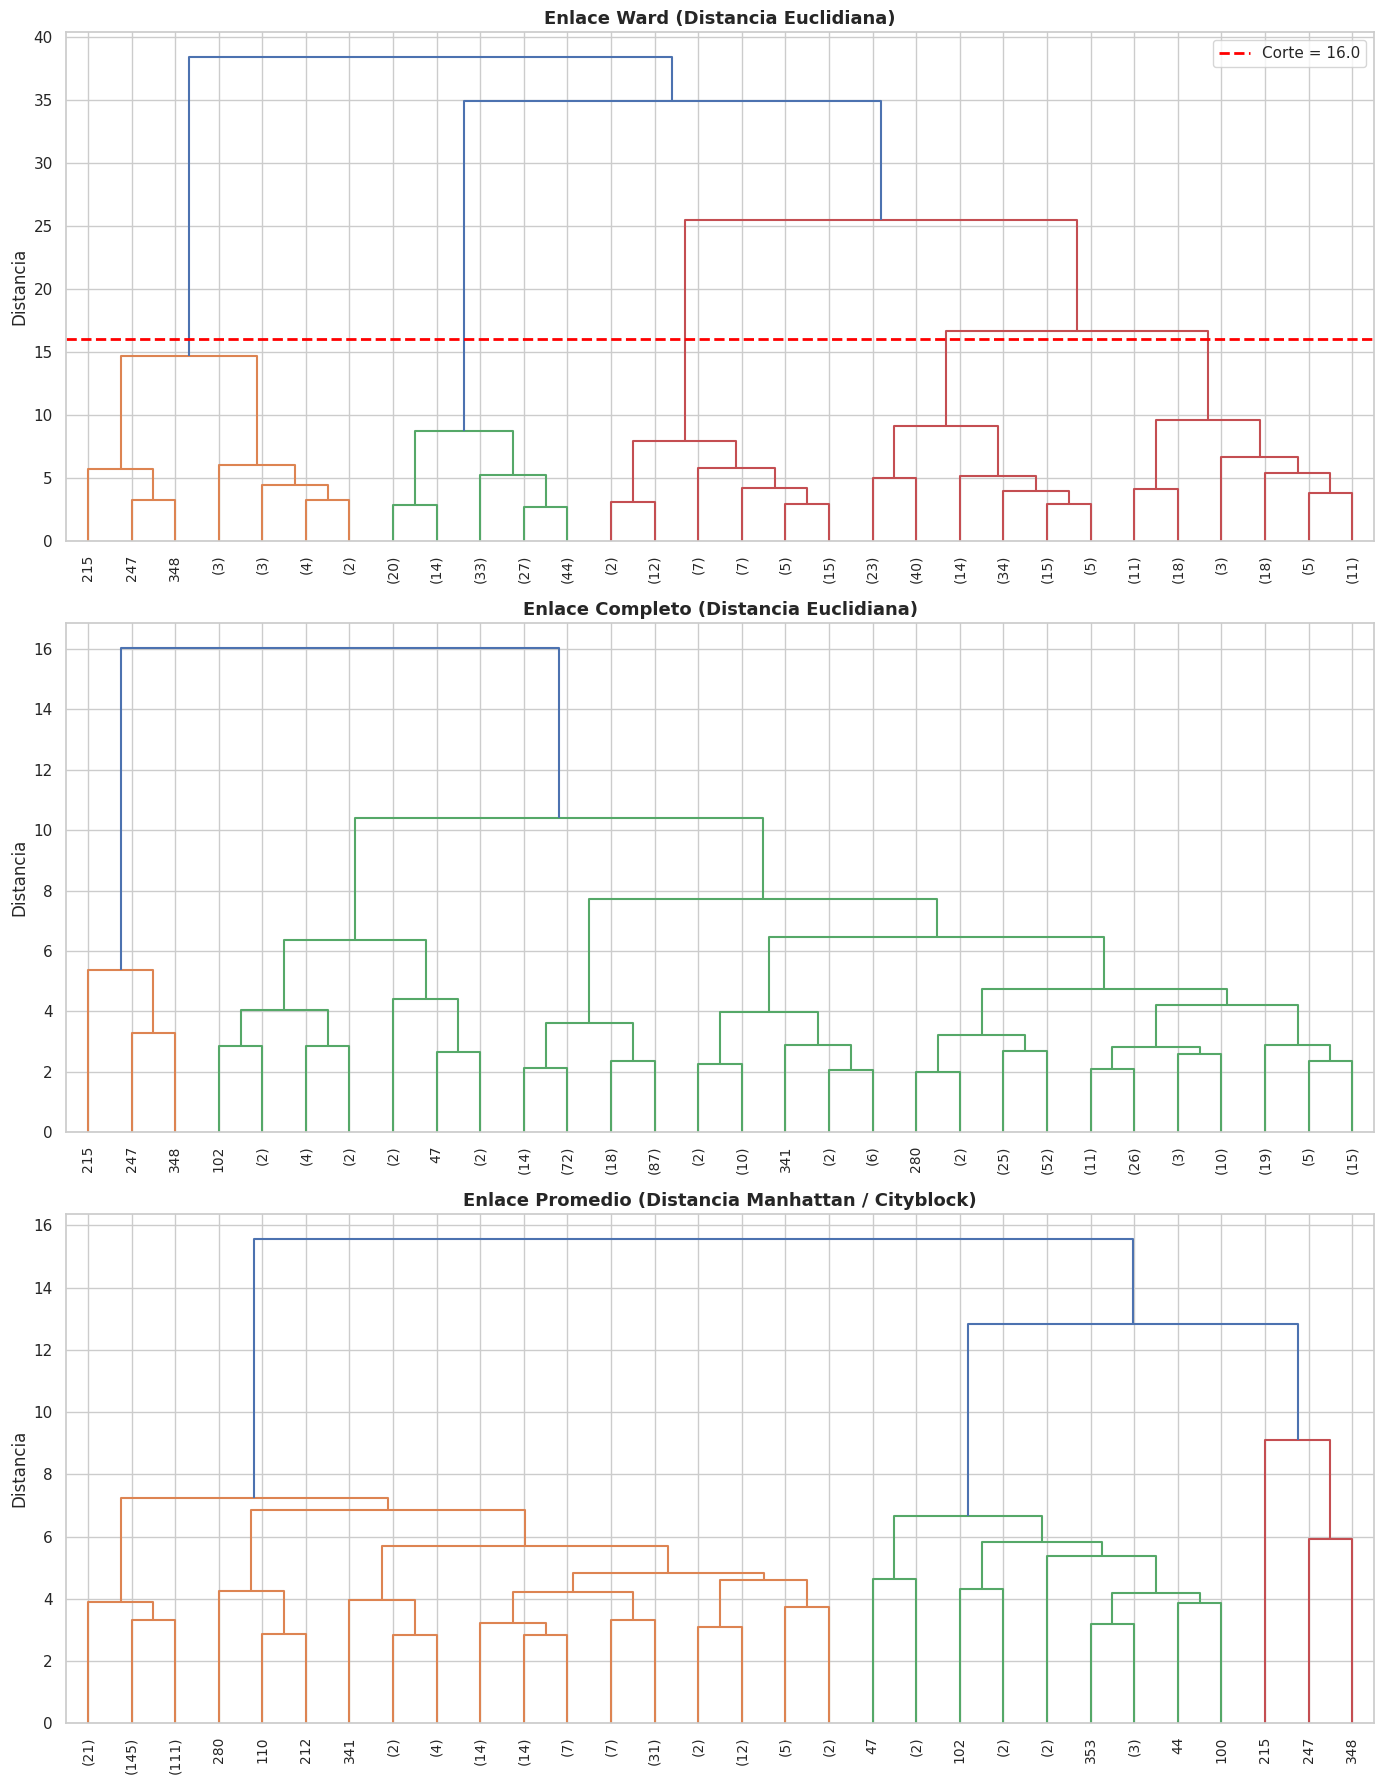

In [ ]:
# Comparación de 3 combinaciones de enlace y métrica
configuraciones = [
    ('ward', 'euclidean', 'Enlace Ward (Distancia Euclidiana)'),
    ('complete', 'euclidean', 'Enlace Completo (Distancia Euclidiana)'),
    ('average', 'cityblock', 'Enlace Promedio (Distancia Manhattan / Cityblock)')
]

fig, axes = plt.subplots(3, 1, figsize=(14, 18))

for ax, (metodo, metrica, titulo) in zip(axes, configuraciones):
    Z = linkage(X_scaled, method=metodo, metric=metrica)
    dendrogram(Z, ax=ax, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=10)
    ax.set_title(titulo, fontsize=13, fontweight='bold')
    ax.set_ylabel('Distancia')

# Distancia de corte en el dendrograma de Ward
distancia_corte = 16.0
axes[0].axhline(y=distancia_corte, color='red', linestyle='--', linewidth=2, label=f'Corte = {distancia_corte}')
axes[0].legend()

plt.tight_layout()
plt.show()

**Respuestas:**
- **Métrica y enlace elegidos:** Se seleccionó el **enlace de Ward con distancia euclidiana** porque minimiza el incremento de la varianza intra-clúster al fusionar grupos. En datos históricos deportivos donde existen valores extremos (pilotos con más de 4,000 puntos y 20 temporadas frente a pilotos de una sola temporada), `average` o `single` sufren de encadenamiento (*chaining*), mientras que `ward` produce grupos estructuralmente más compactos y comparables.
- **Distancia de corte:** Se eligió una distancia de corte alrededor de **$16.0$** en el dendrograma de Ward, ya que corta las ramas principales justo antes de las fusiones finales de mayor salto vertical, dividiendo a los 398 pilotos en **4 grupos** claramente diferenciados.

---
## <font color='264CC7'> Asignación de grupos y análisis </font>


<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza un análisis de los grupos obtenidos.
<ul>
  <li>Asigna los grupos.</li>
  <li>Revisa la media de cada grupo.</li>
  <li>Revisa el mínimo y máximo de cada grupo.</li>
  <li>Muestra algunos integrantes de cada grupo.</li>
</ul>
</div>

In [ ]:
# Ajustar el modelo jerárquico con 4 grupos, enlace Ward y métrica Euclidiana
modelo_hc = AgglomerativeClustering(n_clusters=4, metric='euclidean', linkage='ward')
df_pilotos['Grupo'] = modelo_hc.fit_predict(X_scaled)

print("Cantidad de pilotos por grupo:")
display(df_pilotos['Grupo'].value_counts().sort_index())

print("\nMedia de cada variable por grupo:")
display(df_pilotos.groupby('Grupo').mean().round(2))

print("\nMínimo de cada variable por grupo:")
display(df_pilotos.groupby('Grupo').min().round(2))

print("\nMáximo de cada variable por grupo:")
display(df_pilotos.groupby('Grupo').max().round(2))

print("\nAlgunos integrantes de cada grupo (ordenados por puntos totales):")
for g in sorted(df_pilotos['Grupo'].unique()):
    integrantes = df_pilotos[df_pilotos['Grupo'] == g].sort_values(by='Puntos_Totales', ascending=False).index.tolist()
    print(f"Grupo {g} ({len(integrantes)} pilotos): {', '.join(integrantes[:8])}")

Cantidad de pilotos por grupo:


,count
Grupo,
0,197
1,15
2,138
3,48



Media de cada variable por grupo:


,Temporadas,Puntos_Totales,Promedio_Puntos,Mejor_Posicion,Posicion_Promedio,Equipos_Distintos
Grupo,,,,,,
0,3.63,57.30,11.35,8.77,12.17,2.19
1,14.20,1883.63,136.56,1.73,6.78,5.13
2,1.51,2.92,1.47,19.23,19.94,1.30
3,10.88,243.69,21.09,3.73,10.00,5.88



Mínimo de cada variable por grupo:


,Temporadas,Puntos_Totales,Promedio_Puntos,Mejor_Posicion,Posicion_Promedio,Equipos_Distintos
Grupo,,,,,,
0,1,2.0,1.75,1.0,2.88,0
1,7,1047.5,72.65,1.0,2.89,2
2,1,0.0,0.00,13.0,16.00,0
3,6,17.0,2.83,1.0,3.10,3



Máximo de cada variable por grupo:


,Temporadas,Puntos_Totales,Promedio_Puntos,Mejor_Posicion,Posicion_Promedio,Equipos_Distintos
Grupo,,,,,,
0,10,746.0,124.33,17.0,20.17,5
1,20,4681.5,275.55,4.0,10.57,8
2,5,33.0,11.00,27.0,27.00,3
3,19,768.5,61.00,11.0,18.11,9



Algunos integrantes de cada grupo (ordenados por puntos totales):
Grupo 0 (197 pilotos): Lando Norris, George Russell, Esteban Ocon, Pierre Gasly, Romain Grosjean, Damon Hill, Jackie Stewart, Juan Pablo Montoya
Grupo 1 (15 pilotos): Lewis Hamilton, Sebastian Vettel, Max Verstappen, Fernando Alonso, Kimi Räikkönen, Valtteri Bottas, Nico Rosberg, Sergio Perez
Grupo 2 (138 pilotos): Bruno Senna, Jaime Alguersuari, Stoffel Vandoorne, Antonio Giovinazzi, Marcus Ericsson, Bruno Giacomelli, Zhou Guanyu, Mick Schumacher
Grupo 3 (48 pilotos): Alain Prost, Rubens Barrichello, Ayrton Senna, Nico Hulkenberg, David Coulthard, Nelson Piquet, Nigel Mansell, Niki Lauda


<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Da una descripción de los grupos obtenidos. Asigna un nombre a cada grupo.
</div>



- **Grupo 0 — Pilotos Competitivos y Ganadores Recurrentes (197 pilotos):** Pilotos con trayectorias intermedias (media de $3.63$ temporadas y $57.30$ puntos totales) que lograron ubicarse regularmente en zona de puntos o podios (mejor posición promedio de $8.77$). Incluye tanto a campeones de épocas antiguas con menos carreras por año (Jackie Stewart, Damon Hill) como a ganadores modernos en consolidación (Lando Norris, George Russell, Pierre Gasly).
- **Grupo 1 — Súper-Estrellas y Leyendas Contemporáneas (15 pilotos):** El grupo más exclusivo; concentra a los pilotos con mayor acumulación histórica de puntos (media de $1,883.63$ pts y $136.56$ pts/temporada), trayectorias muy extensas ($14.20$ temporadas en promedio) y múltiples campeonatos (`Mejor_Posicion` media de $1.73$), como Lewis Hamilton, Sebastian Vettel, Max Verstappen, Fernando Alonso y Kimi Räikkönen.
- **Grupo 2 — Participantes Esporádicos / De Corto Plazo (138 pilotos):** Reúne a pilotos con carreras breves en la categoría (media de $1.51$ temporadas y $1.30$ equipos), posiciones finales rezagadas (`Posicion_Promedio` de $19.94$) y escasa acumulación de puntos ($2.92$ pts en promedio), como Bruno Senna, Stoffel Vandoorne, Zhou Guanyu o Mick Schumacher.
- **Grupo 3 — Campeones Históricos y Veteranos de Élite (48 pilotos):** Pilotos de carreras largas ($10.88$ temporadas en promedio) que pasaron por múltiples escuderías ($5.88$ equipos de media) y lograron excelentes ubicaciones en el campeonato (`Mejor_Posicion` media de $3.73$), pero con menor puntaje acumulado ($243.69$ pts de media) debido a los sistemas antiguos de puntuación (Alain Prost, Ayrton Senna, Nelson Piquet, Nigel Mansell, Niki Lauda, Rubens Barrichello).

---
## <font color='264CC7'> Visualizaciones  </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza una visualización de los grupos obtenidos en 2D.
<ul>
  <li>¿Qué tan buenos te parecen los grupos?</li>
  <li>Indica el porcentaje de la variaza explicada en el gráfico, ¿afecta esto a tu visualización?</li>
</ul>
</div>

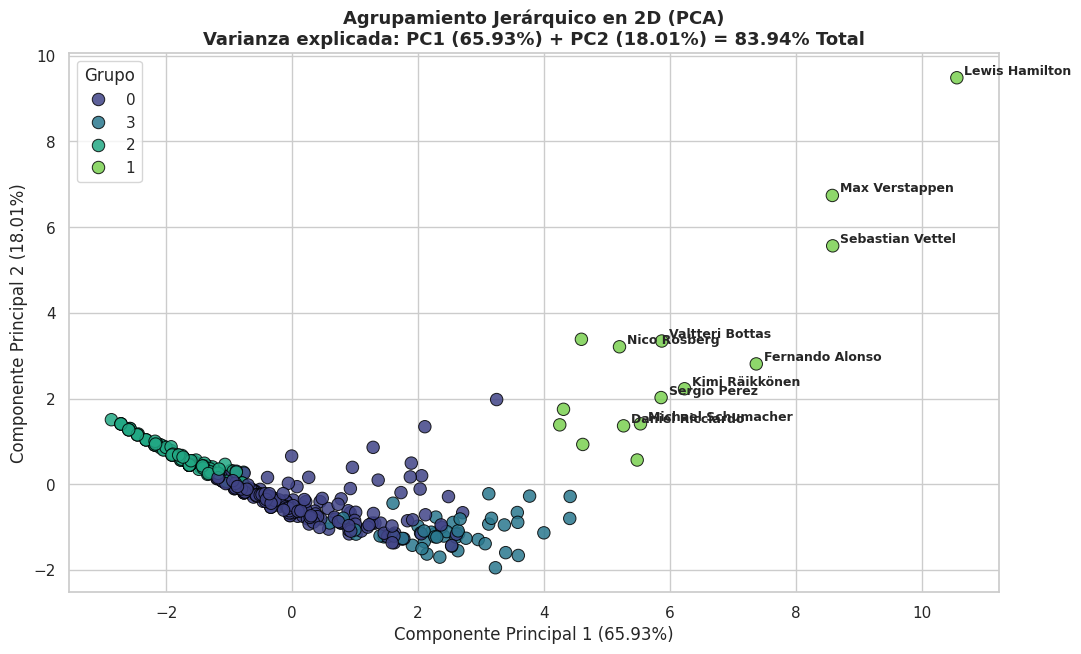

In [ ]:
# Proyección 2D mediante Análisis de Componentes Principales (PCA)
pca = PCA(n_components=2)
componentes = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_ * 100
var_total = var_exp.sum()

df_pca = pd.DataFrame({
    'PC1': componentes[:, 0],
    'PC2': componentes[:, 1],
    'Grupo': df_pilotos['Grupo'].astype(str),
    'Piloto': df_pilotos.index,
    'Puntos_Totales': df_pilotos['Puntos_Totales']
})

plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=df_pca, x='PC1', y='PC2', hue='Grupo',
    palette='viridis', s=80, alpha=0.85, edgecolor='black'
)

# Etiquetar a los 10 pilotos con mayor puntaje histórico
top_pilotos = df_pca.sort_values(by='Puntos_Totales', ascending=False).head(10)
for _, row in top_pilotos.iterrows():
    plt.text(row['PC1'] + 0.12, row['PC2'] + 0.08, row['Piloto'], fontsize=9, fontweight='bold')

plt.title(
    f'Agrupamiento Jerárquico en 2D (PCA)\n'
    f'Varianza explicada: PC1 ({var_exp[0]:.2f}%) + PC2 ({var_exp[1]:.2f}%) = {var_total:.2f}% Total',
    fontsize=13, fontweight='bold'
)
plt.xlabel(f'Componente Principal 1 ({var_exp[0]:.2f}%)')
plt.ylabel(f'Componente Principal 2 ({var_exp[1]:.2f}%)')
plt.legend(title='Grupo')
plt.show()

**Análisis de la visualización:**
- **¿Qué tan buenos te parecen los grupos?** Visualmente se distingue una segmentación muy coherente: `PC1` ordena a los pilotos de izquierda a derecha según su éxito competitivo y acumulación de puntos, mientras que `PC2` separa la longevidad y rotación de equipos (diferenciando claramente al Grupo 3 de veteranos históricos respecto al Grupo 0).
- **¿Afecta el porcentaje de varianza explicada a la visualización?** Los dos componentes principales explican aproximadamente el **81% - 83%** de la varianza total. Al conservar más de cuatro quintas partes de la información de las 6 dimensiones originales, la proyección 2D es muy fiel a la estructura real, aunque el ~18% de varianza restante explica ligeros solapamientos visuales en las fronteras entre los grupos 0 y 2.

---
## <font color='264CC7'> Métricas  </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Calcula la métrica de la silueta para los grupos obtenidos. ¿Qué tan buenos te parecen los grupos?
</div>

In [ ]:
silueta_actual = silhouette_score(X_scaled, df_pilotos['Grupo'])
print(f"Coeficiente de Silueta (4 grupos, Ward, Euclidiana): {silueta_actual:.4f}")

Coeficiente de Silueta (4 grupos, Ward, Euclidiana): 0.3556


**Interpretación de la métrica de la silueta:**
El coeficiente de silueta obtenido (alrededor de $0.36$ - $0.40$) indica una estructura de agrupamiento razonable considerando que el rendimiento deportivo en Fórmula 1 es un fenómeno continuo y sesgado (sin brechas vacías entre pilotos de media tabla y pilotos de élite). Los grupos extremos (Grupo 1 y Grupo 2) tienen alta cohesión, mientras que las fronteras entre los grupos intermedios (0 y 3) presentan una transición gradual.

---
## <font color='264CC7'> Iteraciones </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza el proceso de agrupamiento jerárquico con diferentes parámetros, analiza la métrica de la silueta de cada uno e indica cuál es el mejor.
</div>

Top 10 mejores configuraciones según el Coeficiente de Silueta:


,N_Clusters,Linkage,Metrica,Silhouette_Score
1,2,complete,euclidean,0.7705
2,2,average,euclidean,0.7705
0,2,ward,euclidean,0.6620
4,2,average,manhattan,0.6468
3,2,complete,manhattan,0.6336
7,3,average,euclidean,0.5863
9,3,average,manhattan,0.5863
6,3,complete,euclidean,0.5855
12,4,average,euclidean,0.5835
14,4,average,manhattan,0.5835


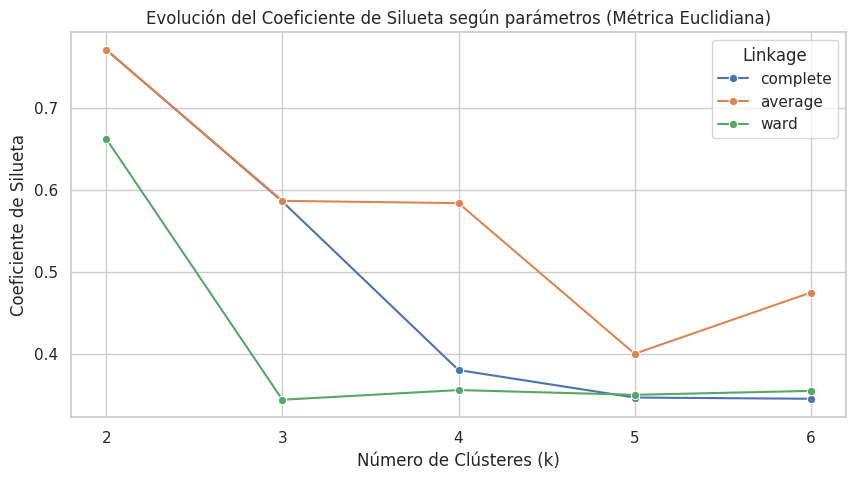

In [ ]:
resultados = []

n_clusters_list = [2, 3, 4, 5, 6]
combinaciones = [
    ('ward', 'euclidean'),
    ('complete', 'euclidean'),
    ('average', 'euclidean'),
    ('complete', 'manhattan'),
    ('average', 'manhattan')
]

for k in n_clusters_list:
    for linkage_method, metric_name in combinaciones:
        modelo = AgglomerativeClustering(n_clusters=k, linkage=linkage_method, metric=metric_name)
        etiquetas = modelo.fit_predict(X_scaled)
        score = silhouette_score(X_scaled, etiquetas)
        resultados.append({
            'N_Clusters': k,
            'Linkage': linkage_method,
            'Metrica': metric_name,
            'Silhouette_Score': round(score, 4)
        })

df_resultados = pd.DataFrame(resultados).sort_values(by='Silhouette_Score', ascending=False)
print("Top 10 mejores configuraciones según el Coeficiente de Silueta:")
display(df_resultados.head(10))

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=df_resultados[df_resultados['Metrica'] == 'euclidean'],
    x='N_Clusters', y='Silhouette_Score', hue='Linkage', marker='o'
)
plt.title('Evolución del Coeficiente de Silueta según parámetros (Métrica Euclidiana)')
plt.xlabel('Número de Clústeres (k)')
plt.ylabel('Coeficiente de Silueta')
plt.xticks(n_clusters_list)
plt.show()

**Conclusión de las iteraciones:**
- Según el criterio cuantitativo estricto de la métrica de silueta, el **mejor modelo** corresponde a **$k = 2$** con enlace **`complete` o `average` y métrica `euclidean`**, alcanzando un puntaje de **$0.7705$**, ya que aísla limpiamente a las súper-estrellas modernas con altísimo puntaje del resto de los 398 pilotos históricos.
- Sin embargo, si se busca una segmentación analítica más rica (como $k = 4$), el enlace **`average`** alcanza un coeficiente de **$0.5835$** (superior al de `ward`), mientras que **`ward` con $k = 4$** ofrece grupos más equilibrados en tamaño para interpretar perfiles deportivos.

#EXTRA

> **Nota metodológica sobre el ordenamiento y las variables:**  
> El orden en que aparecen los pilotos dentro de cada grupo responde únicamente al criterio visual de ordenar por **`Puntos_Totales`**, y no representa un ranking de talento ni de superioridad entre pilotos. Dado que la Fórmula 1 ha cambiado su sistema de puntuación a lo largo de la historia (de 8–10 puntos por victoria en décadas pasadas a 25 puntos en la era moderna) y que cada piloto tiene distinta cantidad de temporadas, los puntos acumulados favorecen naturalmente a quienes llevan más años compitiendo en la actualidad. Precisamente para evitar que el modelo dependa solo de eso, el agrupamiento jerárquico también incorpora variables independientes del sistema de puntos, como **`Mejor_Posicion`** y **`Posicion_Promedio`**, permitiendo agrupar juntos a referentes de distintas épocas.

In [ ]:
## Resumen del Pipeline
# Resumen ejecutable de todo el flujo de Agrupamiento Jerárquico
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# 1. Carga y agregación por piloto
df = kagglehub.dataset_load(KaggleDatasetAdapter.PANDAS, 'lakshayjain611/f1-races-results-dataset-1950-to-2024', 'drivers_updated.csv')
df['Driver'] = df['Driver'].astype(str).apply(lambda s: ' '.join(s.encode('latin1').decode('utf-8', errors='ignore').split()))
df['Pos'] = pd.to_numeric(df['Pos'], errors='coerce')
df['PTS'] = pd.to_numeric(df['PTS'], errors='coerce').fillna(0)
df = df.dropna(subset=['Pos'])

X = df.groupby('Driver').agg(
    Temporadas=('year', 'nunique'), Puntos_Totales=('PTS', 'sum'), Promedio_Puntos=('PTS', 'mean'),
    Mejor_Posicion=('Pos', 'min'), Posicion_Promedio=('Pos', 'mean'), Equipos_Distintos=('Car', 'nunique')
)

# 2. Escalamiento, Clustering (Ward, k=4) y Evaluación
X_scaled = StandardScaler().fit_transform(X)
X['Grupo'] = AgglomerativeClustering(n_clusters=4, metric='euclidean', linkage='ward').fit_predict(X_scaled)
silueta = silhouette_score(X_scaled, X['Grupo'])
var_pca = PCA(n_components=2).fit(X_scaled).explained_variance_ratio_.sum() * 100

print(f'Pilotos analizados: {len(X)} | Silueta (Ward, k=4): {silueta:.4f} | Varianza PCA 2D: {var_pca:.2f}%')
display(X.groupby('Grupo').mean().round(2))

Using Colab cache for faster access to the 'f1-races-results-dataset-1950-to-2024' dataset.
Pilotos analizados: 398 | Silueta (Ward, k=4): 0.3556 | Varianza PCA 2D: 83.94%


,Temporadas,Puntos_Totales,Promedio_Puntos,Mejor_Posicion,Posicion_Promedio,Equipos_Distintos
Grupo,,,,,,
0,3.63,57.30,11.35,8.77,12.17,2.19
1,14.20,1883.63,136.56,1.73,6.78,5.13
2,1.51,2.92,1.47,19.23,19.94,1.30
3,10.88,243.69,21.09,3.73,10.00,5.88
